In [2]:
import os
import math

# Select the backend before importing Keras. Restart the kernel after changing it.
os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch
import matplotlib.pyplot as plt

assert keras.backend.backend() == "torch", "Restart the kernel and run this cell first."


# Set global policy to leverage Metal's FP16 architecture
# policy = keras.mixed_precision.Policy("mixed_bfloat16")
# keras.mixed_precision.set_global_policy(policy)


def plot_samples(data,
                 n=5,
                 max_cols=5,
                 cmap="tab20",
                 filename=None
                 ):
    n = min(len(data), n)
    if n < max_cols:
        rows = 1
        cols = n
    else:
        rows = math.ceil(n / max_cols)
        cols = max_cols
    print(f"rows: {rows}, cols: {cols}")
    fig, ax = plt.subplots(nrows=rows, ncols=cols, sharex=True, sharey=True, figsize=(20, 10))
    #ax = ax.flatten()
    index = 0
    for i in range(rows):
        for j in range(cols):
            img = data[index]
            index += 1
            ax[i, j].imshow(img, cmap=cmap, interpolation='nearest')
            if index >= n:
                break
    plt.tight_layout()
    plt.show()
    if filename:
        plt.savefig(filename, dpi=300)


### Load MNIST dataset and preprocess it

In [3]:
(mnist_images, mnist_labels), (mnist_images_test, mnist_labels_test) = keras.datasets.mnist.load_data()
print(mnist_images.shape)
mnist_images[0, :, 5:]

(60000, 28, 28)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18, 126, 136,
        175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
       [  0,   0,   0,  30,  36,  94, 154, 170, 253, 253, 253, 253, 253,
        225, 172, 253, 242, 195,  64,   0,   0,   0,   0],
       [  0,   0,  49, 238, 253, 253, 253, 253, 253, 253, 253, 253, 251,
   

In [4]:
X_train = mnist_images.astype("float32") / 255.0
y_train = mnist_labels.astype("int32")
X_test = mnist_images_test.astype("float32") / 255.0
y_test = mnist_labels_test.astype("int32")

X_train[0, :, 5:]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.   

In [5]:
y_train_oh = keras.utils.to_categorical(y_train, num_classes=10)
y_train_oh[:5, :]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

rows: 4, cols: 5


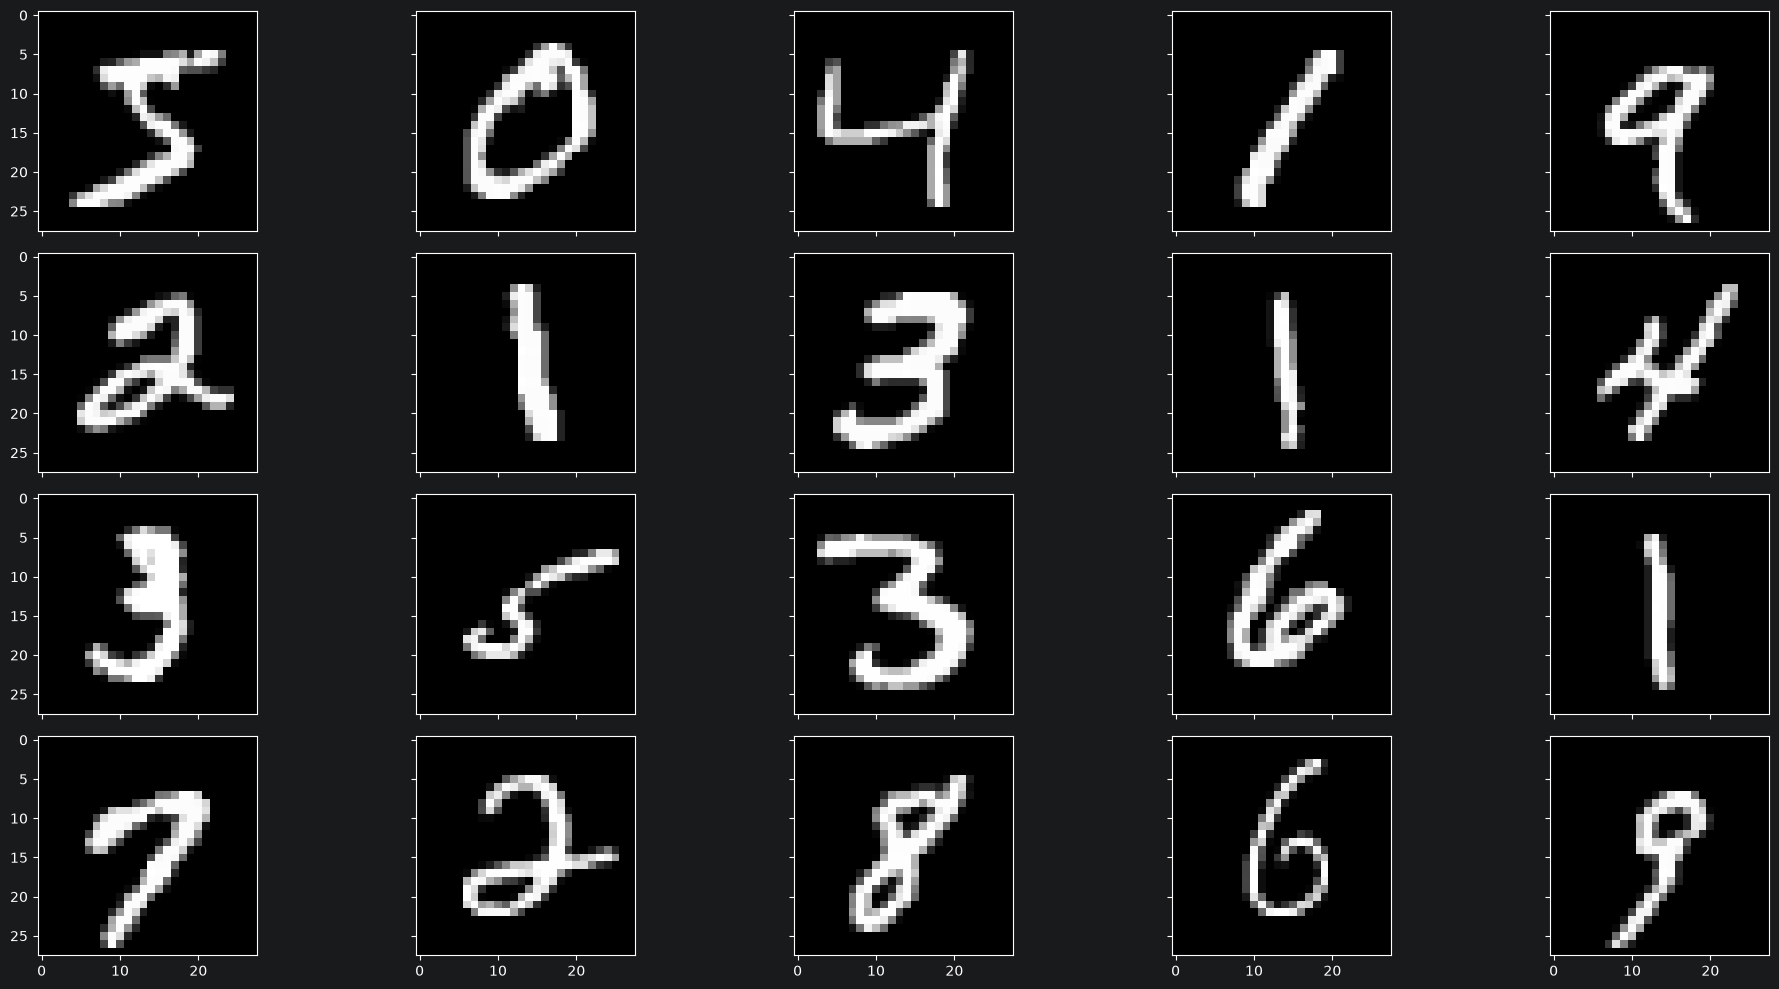

In [6]:
plot_samples(X_train, n=20, cmap="gray")

### Build and train a simple neural network model

In [7]:
base_model = keras.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
base_model.compile(
        # optimizer=keras.optimizers.Adam(learning_rate=0.002),
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
        )

In [9]:
base_model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=2,
        verbose=1,
        validation_split=0.1
        )

Epoch 1/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8526 - loss: 0.5803 - val_accuracy: 0.9232 - val_loss: 0.2989
Epoch 2/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9068 - loss: 0.3379 - val_accuracy: 0.9288 - val_loss: 0.2619


In [10]:
base_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9178 - loss: 0.3026


[0.30260708928108215, 0.9178000092506409]

rows: 2, cols: 5


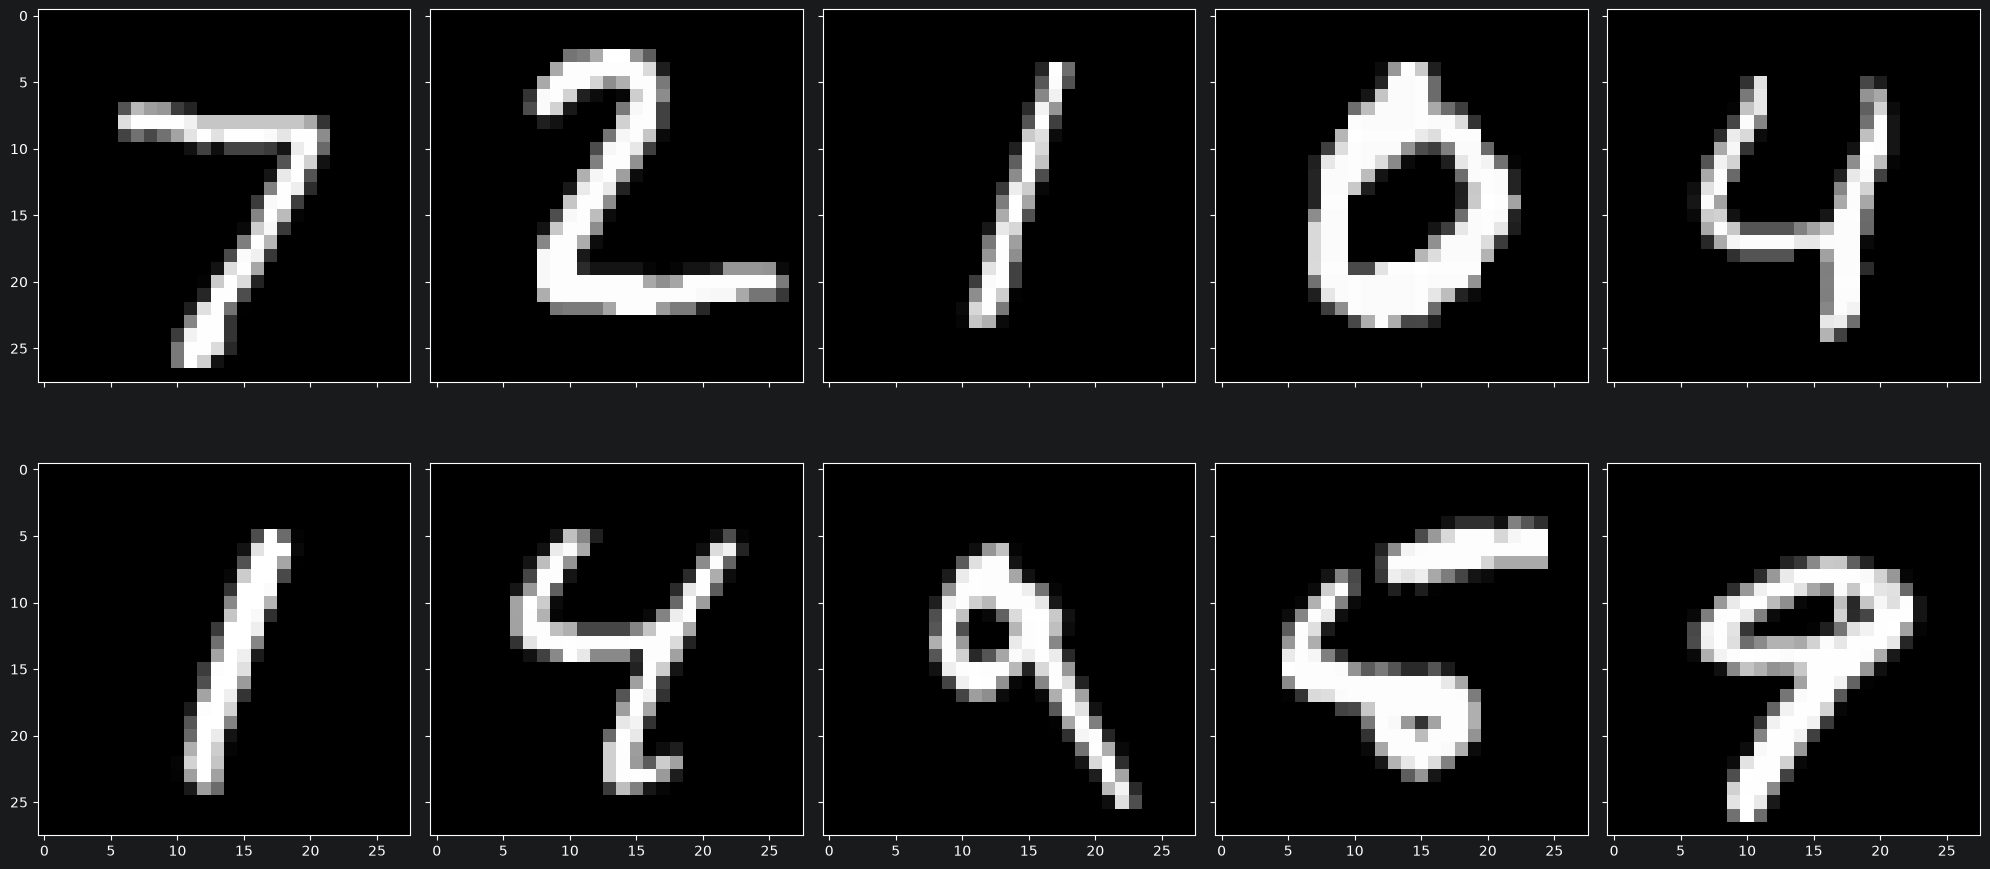

In [31]:
plot_samples(X_test, n=10, cmap="gray")

In [ ]:
images = X_test[:10]
y_predict = base_model.predict(images)
print(y_predict.argmax(axis=1))
print(y_test[:10])

### Learning rate and optimizer experiments

In [40]:
m1 = keras.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m1.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.00001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
        )


In [41]:
m1.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=10,
        verbose=1,
        validation_split=0.1
        )
m1.evaluate(X_test, y_test)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.1931 - loss: 2.2372 - val_accuracy: 0.3020 - val_loss: 2.0811
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.3963 - loss: 1.9690 - val_accuracy: 0.5222 - val_loss: 1.8293
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5775 - loss: 1.7490 - val_accuracy: 0.6588 - val_loss: 1.6190
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6718 - loss: 1.5646 - val_accuracy: 0.7315 - val_loss: 1.4421
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7244 - loss: 1.4094 - val_accuracy: 0.7738 - val_loss: 1.2931
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7549 - loss: 1.2786 - val_accuracy: 0.8030 - val_loss: 1.1676
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7761 - loss: 1.1686 - val_accuracy: 0.8217 - val_loss: 1.0622
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7912 - loss: 1.0757 - val_accuracy: 0.

[0.875724732875824, 0.8281999826431274]

In [42]:
m3 = keras.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m3.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
        )
m3.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=10,
        verbose=1,
        validation_split=0.1
        )
m3.evaluate(X_test, y_test)


Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7116 - loss: 4.5118 - val_accuracy: 0.7327 - val_loss: 4.2667
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7360 - loss: 4.2081 - val_accuracy: 0.7547 - val_loss: 3.9227
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7421 - loss: 4.1175 - val_accuracy: 0.7478 - val_loss: 4.0400
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7417 - loss: 4.1348 - val_accuracy: 0.7687 - val_loss: 3.7184
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7468 - loss: 4.0559 - val_accuracy: 0.7653 - val_loss: 3.7668
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7444 - loss: 4.0957 - val_accuracy: 0.7665 - val_loss: 3.7355
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7664 - loss: 3.7390 - val_accuracy: 0.8098 - val_loss: 3.0408
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8023 - loss: 3.1575 - val_accuracy: 0.

[2.858330488204956, 0.821399986743927]

### Classification threshold experiments

In [37]:
images = X_test[:20]
model = base_model


def predict(model, images, threshold=0.9):
    y_proba = model.predict(images)
    y_pred = y_proba.argmax(axis=1)
    y_predict = [int(y_pred[i]) if y_proba[i, y_pred[i]] >= threshold else -1 for i in range(len(y_pred))]
    # for i in range(len(y_predict)):
    #     if y_proba[i, y_predict[i]] < threshold:
    #         y_predict[i] = -1
    return y_predict


predict(base_model, images, threshold=0.8)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


[7, 2, 1, 0, 4, 1, 4, 9, 6, 9, 0, -1, 9, 0, 1, 5, 9, 7, -1, 4]

### Model architecture experiments (and Just in Time compilation)

In [26]:
model = keras.models.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(20, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
        )

In [27]:
import time

early_stopping = keras.callbacks.EarlyStopping(
        patience=2, restore_best_weights=True, min_delta=0.005,
        monitor="val_accuracy", mode="max"
        )
runtime = time.time()
model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping],
        validation_split=0.1
        )
print(f"Runtime: {time.time() - runtime:.2f} seconds")
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {accuracy:.4f} (bzw. {accuracy * 100:.2f}%)")

Epoch 1/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8616 - loss: 0.4954 - val_accuracy: 0.9323 - val_loss: 0.2462
Epoch 2/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9236 - loss: 0.2696 - val_accuracy: 0.9458 - val_loss: 0.2030
Epoch 3/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9354 - loss: 0.2290 - val_accuracy: 0.9488 - val_loss: 0.1890
Epoch 4/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9430 - loss: 0.2028 - val_accuracy: 0.9553 - val_loss: 0.1674
Epoch 5/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9473 - loss: 0.1844 - val_accuracy: 0.9552 - val_loss: 0.1610
Epoch 6/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9513 - loss: 0.1701 - val_accuracy: 0.9588 - val_loss: 0.1527
Runtime: 27.82 seconds
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9423 - loss: 0.1956
Test Loss: 0.1956, Test Accuracy: 0.9423 (bzw. 94.23%)


In [28]:
model = keras.models.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(20, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=True
        )

early_stopping = keras.callbacks.EarlyStopping(
        patience=2, restore_best_weights=True, min_delta=0.005,
        monitor="val_accuracy", mode="max"
        )
runtime = time.time()
model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping],
        validation_split=0.1
        )
print(f"Runtime: {time.time() - runtime:.2f} seconds")
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {accuracy:.4f} (bzw. {accuracy * 100:.2f}%)")

Epoch 1/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.8578 - loss: 0.5170 - val_accuracy: 0.9353 - val_loss: 0.2262
Epoch 2/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9293 - loss: 0.2524 - val_accuracy: 0.9493 - val_loss: 0.1823
Epoch 3/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9390 - loss: 0.2147 - val_accuracy: 0.9550 - val_loss: 0.1617
Epoch 4/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9448 - loss: 0.1908 - val_accuracy: 0.9572 - val_loss: 0.1483
Epoch 5/100
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9497 - loss: 0.1739 - val_accuracy: 0.9575 - val_loss: 0.1448
Runtime: 16.37 seconds
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9415 - loss: 0.1970 
Test Loss: 0.1970, Test Accuracy: 0.9415 (bzw. 94.15%)


### Best and fastest model architecture (jit_compile=True)

In [43]:
model = keras.models.Sequential(
        [
                keras.layers.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(144, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=True
        )

early_stopping = keras.callbacks.EarlyStopping(
        patience=2, restore_best_weights=True, min_delta=0.005,
        monitor="val_accuracy", mode="max"
        )
runtime = time.time()
model.fit(
        X_train,
        y_train,
        batch_size=128,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping],
        validation_split=0.1
        )
print(f"Runtime: {time.time() - runtime:.2f} seconds")
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {accuracy:.4f} (bzw. {accuracy * 100:.2f}%)")

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8990 - loss: 0.3675 - val_accuracy: 0.9550 - val_loss: 0.1701
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9508 - loss: 0.1707 - val_accuracy: 0.9695 - val_loss: 0.1184
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9652 - loss: 0.1211 - val_accuracy: 0.9730 - val_loss: 0.0994
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9729 - loss: 0.0932 - val_accuracy: 0.9725 - val_loss: 0.0942
Runtime: 10.57 seconds
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9605 - loss: 0.1374
Test Loss: 0.1374, Test Accuracy: 0.9605 (bzw. 96.05%)


### Save and load the model

In [44]:
model.save("../models/mnist_digits_144_10.keras")

In [45]:
m = keras.models.load_model("../models/mnist_digits_144_10.keras")
m.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 144)            │       113,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,472 (1.31 MB)

 Trainable params: 114,490 (447.23 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 228,982 (894.46 KB)

In [46]:
m.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9605 - loss: 0.1374


[0.13740529119968414, 0.9605000019073486]

In [47]:
predict(m, X_test[10:20], threshold=0.9)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step


[0, 6, 9, 0, 1, 5, 9, 7, -1, 4]